# Lab 20.2: An Evaluation Suite for Five Explainers

*Explainable AI in Practice*, Chapter 20. Run-only notebook with one optional edit (Part G).

This notebook rebuilds the chapter's running example: a small neural network that scores the default risk of **synthetic** loan applicants, explained by five methods (plain gradient, gradient times input, occlusion, exact Shapley values and a LIME-style local surrogate), and evaluated by seven tests. The code, data and seeds are those of `figures/scripts/ch20_figs.py` in the book repository, so the numbers match the chapter.

The data is invented: ten standardized features, of which income, debt ratio and missed payments always affect the true risk, utilization matters only when missed payments are above average, and loan amount is correlated with debt ratio but has no effect. Because the true structure is known, a planted-truth test is possible. No real person's data is used.

Environment: `env/requirements.txt` (numpy, scipy, scikit-learn, matplotlib), kernel `xai-lab-venv`. Running time: about three minutes on a laptop CPU.

In [1]:
import warnings, itertools, time
warnings.filterwarnings('ignore')
from math import factorial
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score
import sklearn, scipy
print('numpy', np.__version__, '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)
T0 = time.time()

numpy 2.2.6 | scikit-learn 1.7.2 | scipy 1.15.3


## Part A: data, model and five explanation methods

The cell below holds every function the lab uses. Read the docstrings; you do not need to change anything.

In [2]:
FEATURES = ["income", "debt_ratio", "missed_payments", "utilization", "loan_amount",
            "file_age", "num_accounts", "inquiries", "job_tenure", "region_code"]
METHODS = ["Gradient", "Gradient x input", "Occlusion", "SHAP (exact)", "LIME-style"]
COLORS = {"Gradient": "#1C5D99", "Gradient x input": "#C8551B", "Occlusion": "#12807A",
          "SHAP (exact)": "#6B4AA0", "LIME-style": "#A87B00", "Random order": "#5F6B7A"}
D = len(FEATURES)


# ---------------------------------------------------------------- data and model
def make_data(n=4000, seed=0):
    """Standardized synthetic credit-style data. Only income, debt_ratio and missed_payments
    enter the true risk everywhere; utilization matters only when missed_payments is above
    average; loan_amount is correlated with debt_ratio (r about 0.8) but has no effect."""
    r = np.random.default_rng(seed)
    X = r.normal(size=(n, D))
    X[:, 4] = 0.8 * X[:, 1] + 0.6 * r.normal(size=n)      # loan_amount ~ debt_ratio
    X[:, 7] = 0.5 * X[:, 6] + np.sqrt(0.75) * r.normal(size=n)  # inquiries ~ num_accounts
    z = -0.4 - 1.0 * X[:, 0] + 1.2 * X[:, 1] + 0.9 * X[:, 2] + 1.0 * X[:, 3] * (X[:, 2] > 0)
    y = (r.random(n) < 1 / (1 + np.exp(-1.5 * z))).astype(int)
    return X, y


def true_relevant(x):
    """Features with an effect on the true risk at x (the planted answer)."""
    rel = {0, 1, 2}
    if x[2] > 0:
        rel.add(3)
    return rel


def fit_model(X, y, seed=0):
    m = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=800, random_state=seed)
    return m.fit(X, y)


def f(m, X):
    return m.predict_proba(np.atleast_2d(X))[:, 1]


# ---------------------------------------------------------------- five explanation methods
def gradient(m, x, eps=1e-3):
    E = np.eye(D) * eps
    return (f(m, x + E) - f(m, x - E)) / (2 * eps)


def explain(m, x, method, mu, background, seed=0):
    if method == "Gradient":
        return gradient(m, x)
    if method == "Gradient x input":
        return gradient(m, x) * (x - mu)
    if method == "Occlusion":
        Z = np.tile(x, (D, 1)); Z[np.arange(D), np.arange(D)] = mu
        return f(m, x)[0] - f(m, Z)
    if method == "SHAP (exact)":
        return shapley(m, x, background)
    if method == "LIME-style":
        r = np.random.default_rng(seed)
        Z = x + r.normal(size=(1000, D))
        w = np.exp(-((Z - x) ** 2).sum(1) / (0.75 * np.sqrt(D)) ** 2)
        A = np.column_stack([np.ones(len(Z)), Z - x]) * np.sqrt(w)[:, None]
        b = f(m, Z) * np.sqrt(w)
        coef = np.linalg.solve(A.T @ A + np.diag([0] + [1.0] * D), A.T @ b)
        return coef[1:]
    raise ValueError(method)


SUBSETS = [S for k in range(D) for S in itertools.combinations(range(D), k)]
WEIGHT = {k: factorial(k) * factorial(D - k - 1) / factorial(D) for k in range(D)}


def shapley(m, x, background):
    """Exact interventional Shapley values of f(x) against a background set (2^10 coalitions)."""
    masks = np.zeros((2 ** D, D), bool)
    for i in range(2 ** D):
        masks[i] = [(i >> j) & 1 for j in range(D)]
    nb = len(background)
    Z = np.repeat(background[None], 2 ** D, 0)            # coalitions x background x D
    Z = np.where(masks[:, None, :], x[None, None, :], Z)
    v = f(m, Z.reshape(-1, D)).reshape(2 ** D, nb).mean(1)
    idx = masks @ (1 << np.arange(D))
    val = np.empty(2 ** D); val[idx] = v
    phi = np.zeros(D)
    sizes = masks.sum(1)
    for i in range(2 ** D):
        S = masks[i]
        for j in np.where(~S)[0]:
            phi[j] += WEIGHT[sizes[i]] * (val[i | (1 << j)] - val[i])
    return phi


# ---------------------------------------------------------------- evaluation tests
def supportive(attr, pred):
    """Attribution toward the predicted class (positive = supports the decision)."""
    return attr if pred == 1 else -attr


def curve(m, x, order, fill, mode="deletion"):
    """Predicted-class probability as features are removed (deletion) or restored (insertion)
    in the given order. fill(x_mod, removed_mask) returns the rows with removed features replaced."""
    pred = int(f(m, x)[0] >= 0.5)
    out = []
    for k in range(D + 1):
        removed = np.zeros(D, bool)
        if mode == "deletion":
            removed[order[:k]] = True
        else:
            removed[order[k:]] = True
        p = f(m, fill(x, removed)).mean()
        out.append(p if pred == 1 else 1 - p)
    return np.array(out)


def auc(c):
    return float(np.trapezoid(c, dx=1 / (len(c) - 1)))


def make_fills(Xtr, mu, seed=0):
    r = np.random.default_rng(seed)
    draws = Xtr[r.integers(0, len(Xtr), 20)]             # 20 marginal draws per feature

    def mean_fill(x, removed):
        z = x.copy(); z[removed] = mu[removed]; return z[None]

    def marginal_fill(x, removed):
        Z = np.tile(x, (len(draws), 1))
        Z[:, removed] = r.permuted(draws, axis=0)[:, removed]
        return Z

    def neighbor_fill(x, removed):
        if removed.all():
            return mean_fill(x, removed)
        if not removed.any():
            return x[None]
        keep = ~removed
        d = ((Xtr[:, keep] - x[keep]) ** 2).sum(1)
        nn = Xtr[np.argsort(d)[:20]]                       # 20 nearest rows on the kept features
        Z = np.tile(x, (20, 1)); Z[:, removed] = nn[:, removed]
        return Z
    return {"Mean value": mean_fill, "Random draw": marginal_fill, "Nearest neighbors": neighbor_fill}


def topk(a, k=3):
    return list(np.argsort(-np.abs(a))[:k])


def jaccard(a, b, k=3):
    A, B = set(topk(a, k)), set(topk(b, k))
    return len(A & B) / len(A | B)


def feature_agreement(a, b, k=3):
    return len(set(topk(a, k)) & set(topk(b, k))) / k


def signed_rank_agreement(a, b, k=3):
    ta, tb = topk(a, k), topk(b, k)
    return sum(ta[i] == tb[i] and np.sign(a[ta[i]]) == np.sign(b[tb[i]]) for i in range(k)) / k


# ---------------------------------------------------------------- run everything once
def run(n_explain=200, seed=0):
    """Data, model (seed = network initialization), background and the five methods' attributions."""
    X, y = make_data()
    Xtr, ytr, Xte, yte = X[:3000], y[:3000], X[3000:], y[3000:]
    m = fit_model(Xtr, ytr, seed)
    mu = Xtr.mean(0)
    rb = np.random.default_rng(1)
    bg = Xtr[rb.choice(len(Xtr), 50, replace=False)]
    print("test AUC:", round(roc_auc_score(yte, f(m, Xte)), 3))
    xs = Xte[:n_explain]
    A = {meth: np.array([explain(m, x, meth, mu, bg) for x in xs]) for meth in METHODS}
    return dict(X=X, y=y, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, m=m, mu=mu, bg=bg, xs=xs, A=A)


def evaluate_curves(R, fill_name="Mean value", n=200):
    m, xs, A = R["m"], R["xs"][:n], R["A"]
    fill = make_fills(R["Xtr"], R["mu"])[fill_name]
    res = {}
    for meth in METHODS:
        dels, ins = [], []
        for x, a in zip(xs, A[meth][:n]):
            pred = int(f(m, x)[0] >= 0.5)
            order = np.argsort(-supportive(a, pred))
            dels.append(curve(m, x, order, fill, "deletion"))
            ins.append(curve(m, x, order, fill, "insertion"))
        res[meth] = (np.mean(dels, 0), np.mean(ins, 0))
    r = np.random.default_rng(7)
    dels, ins = [], []
    for x in xs:
        for _ in range(10):
            order = r.permutation(D)
            dels.append(curve(m, x, order, fill, "deletion"))
            ins.append(curve(m, x, order, fill, "insertion"))
    res["Random order"] = (np.mean(dels, 0), np.mean(ins, 0))
    return res


def referee_scores(R):
    """Deletion area for each method under three replacement strategies."""
    scores = {}
    for fill_name in ("Mean value", "Random draw", "Nearest neighbors"):
        res = evaluate_curves(R, fill_name, n=200)
        scores[fill_name] = {k: auc(v[0]) for k, v in res.items()}
    print("deletion AUC by referee:", {k: {m: round(s, 3) for m, s in v.items()} for k, v in scores.items()})
    return scores


def planted_and_randomization(R):
    """Planted-truth precision and the data randomization test (shuffled labels)."""
    xs, A = R["xs"], R["A"]
    prec = {}
    for meth in METHODS:
        p = []
        for x, a in zip(xs, A[meth]):
            rel = true_relevant(x)
            p.append(len(set(topk(a, len(rel))) & rel) / len(rel))
        prec[meth] = float(np.mean(p))
    r = np.random.default_rng(3)
    rand_prec = float(np.mean([len(set(r.permutation(D)[:len(true_relevant(x))]) & true_relevant(x)) / len(true_relevant(x)) for x in xs for _ in range(20)]))
    ysh = np.random.default_rng(5).permutation(R["ytr"])
    m_rand = fit_model(R["Xtr"], ysh)
    corr = {}
    for meth in METHODS:
        c = []
        for i, x in enumerate(xs[:100]):
            a2 = explain(m_rand, x, meth, R["mu"], R["bg"])
            c.append(spearmanr(np.abs(A[meth][i]), np.abs(a2)).statistic)
        corr[meth] = float(np.nanmean(c))
    print("planted precision:", {k: round(v, 3) for k, v in prec.items()}, "random:", round(rand_prec, 3))
    print("randomization rank correlation (|attr|, trained vs shuffled labels):", {k: round(v, 3) for k, v in corr.items()})
    print("shuffled-label model test AUC:", round(roc_auc_score(R["yte"], f(m_rand, R["Xte"])), 3))
    return prec, rand_prec, corr


def stability(R, n=100, draws=5):
    """Top-3 Jaccard under small input changes (same decision) and under reruns."""
    m, xs, A, mu = R["m"], R["xs"][:n], R["A"], R["mu"]
    r = np.random.default_rng(11)
    noise, rerun = {}, {}
    for meth in METHODS:
        jn, jr = [], []
        for i, x in enumerate(xs):
            pred = f(m, x)[0] >= 0.5
            for d in range(draws):
                x2 = x + r.normal(0, 0.1, D)
                if (f(m, x2)[0] >= 0.5) != pred:
                    continue
                jn.append(jaccard(A[meth][i], explain(m, x2, meth, mu, R["bg"])))
            if meth == "LIME-style":
                jr += [jaccard(A[meth][i], explain(m, x, meth, mu, R["bg"], seed=s)) for s in range(1, 4)]
            elif meth == "SHAP (exact)":
                for s in range(1, 4):
                    bg2 = R["Xtr"][np.random.default_rng(100 + s).choice(len(R["Xtr"]), 50, replace=False)]
                    jr.append(jaccard(A[meth][i], shapley(m, x, bg2)))
            else:
                jr.append(1.0)
        noise[meth], rerun[meth] = float(np.mean(jn)), float(np.mean(jr))
    print("stability top-3 Jaccard, input noise:", {k: round(v, 3) for k, v in noise.items()})
    print("stability top-3 Jaccard, reruns:", {k: round(v, 3) for k, v in rerun.items()})
    return noise, rerun


def disagreement(R):
    """Pairwise feature agreement, signed rank agreement (top 3) and rank correlation."""
    A, n = R["A"], len(R["xs"])
    FA = np.ones((len(METHODS), len(METHODS))); SRA = np.ones_like(FA); RC = np.ones_like(FA)
    for i, j in itertools.combinations(range(len(METHODS)), 2):
        a, b = A[METHODS[i]], A[METHODS[j]]
        FA[i, j] = FA[j, i] = np.mean([feature_agreement(a[t], b[t]) for t in range(n)])
        SRA[i, j] = SRA[j, i] = np.mean([signed_rank_agreement(a[t], b[t]) for t in range(n)])
        RC[i, j] = RC[j, i] = np.nanmean([spearmanr(a[t], b[t]).statistic for t in range(n)])
    iu = np.triu_indices(len(METHODS), 1)
    print("feature agreement:\n", np.round(FA, 2)); print("signed rank agreement:\n", np.round(SRA, 2))
    print("mean FA", round(FA[iu].mean(), 3), "mean SRA", round(SRA[iu].mean(), 3))
    return FA, SRA, RC


def scorecard_table(dres, refs, prec, corr, noise, rerun):
    """Columns of the scorecard: (name, values per method, higher is better)."""
    return [("Deletion\n(mean fill)", {k: auc(dres[k][0]) for k in METHODS}, False),
            ("Deletion\n(neighbor fill)", refs["Nearest neighbors"], False),
            ("Insertion\n(mean fill)", {k: auc(dres[k][1]) for k in METHODS}, True),
            ("Planted\ntruth", prec, True),
            ("Randomization\n(|corr|)", {k: abs(corr[k]) for k in METHODS}, False),
            ("Stability\n(input moved)", noise, True),
            ("Stability\n(rerun)", rerun, True)]


def scorecard(dres, refs, prec, corr, noise, rerun, ax=None):
    """Draw the scorecard; cells are colored by rank within each column (ties share a rank)."""
    cols = scorecard_table(dres, refs, prec, corr, noise, rerun)
    rank = np.zeros((len(METHODS), len(cols)))
    for j, (_, vals, higher) in enumerate(cols):
        for i, k in enumerate(METHODS):   # ties share a rank
            better = [q for q in METHODS if (round(vals[q], 2) > round(vals[k], 2) if higher else round(vals[q], 2) < round(vals[k], 2))]
            rank[i, j] = len(better) + 1
    if ax is None:
        fig, ax = plt.subplots(figsize=(7.8, 3.3))
    ax.imshow(rank, cmap="Blues_r", vmin=1, vmax=7, aspect="auto")
    for i, k in enumerate(METHODS):
        for j, (_, vals, _) in enumerate(cols):
            ax.text(j, i, f"{vals[k]:.2f}", ha="center", va="center", fontsize=9.5,
                    color="white" if rank[i, j] <= 2 else "#1F2933", weight="bold" if rank[i, j] == 1 else "normal")
    ax.set_xticks(range(len(cols)), [c[0] for c in cols], fontsize=8.6)
    ax.set_yticks(range(len(METHODS)), METHODS, fontsize=9.5)
    ax.xaxis.tick_top()
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xticks(np.arange(len(cols) + 1) - 0.5, minor=True); ax.set_yticks(np.arange(len(METHODS) + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
    ax.text(len(cols) / 2 - 0.5, len(METHODS) - 0.25, "Darker cell = better rank in that column (bold = best). Lower is better for deletion and randomization.",
            ha="center", va="top", fontsize=8.4, color="#5F6B7A")
    return ax




In [3]:
SEED = 0   # Part G: optional edit
R = run(seed=SEED)
print('explained', len(R['xs']), 'test applicants')

test AUC: 0.877


explained 200 test applicants


**Checkpoint 1.** Test AUC 0.877.

In [4]:
i = 0
x = R['xs'][i]
print('applicant 1, predicted risk', round(f(R['m'], x)[0], 3), '| truly relevant:', [FEATURES[j] for j in sorted(true_relevant(x))])
for meth in METHODS:
    a = R['A'][meth][i]
    print(f"{meth:18s}", [(FEATURES[j], round(float(a[j]), 2)) for j in topk(a, 3)])

applicant 1, predicted risk 0.234 | truly relevant: ['income', 'debt_ratio', 'missed_payments']
Gradient           [('missed_payments', 1.07), ('income', -0.62), ('inquiries', 0.58)]
Gradient x input   [('missed_payments', -1.75), ('region_code', -0.84), ('income', 0.69)]
Occlusion          [('missed_payments', -0.76), ('utilization', -0.74), ('income', 0.22)]
SHAP (exact)       [('missed_payments', -0.4), ('debt_ratio', 0.28), ('income', 0.16)]
LIME-style         [('missed_payments', 0.29), ('debt_ratio', 0.15), ('income', -0.11)]


**Checkpoint 2.** The gradient gives `missed_payments` a positive sign (more missed payments would raise risk); gradient times input gives it a negative sign (this applicant's few missed payments lowered risk). Gradient times input puts `region_code`, a pure noise feature, second.

## Part B: deletion and insertion

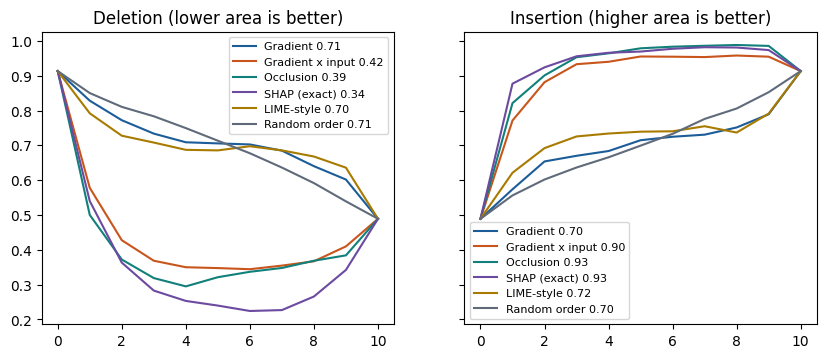

Gradient           deletion 0.708  insertion 0.699
Gradient x input   deletion 0.425  insertion 0.900
Occlusion          deletion 0.395  insertion 0.926
SHAP (exact)       deletion 0.344  insertion 0.931
LIME-style         deletion 0.699  insertion 0.724
Random order       deletion 0.705  insertion 0.703


In [5]:
dres = evaluate_curves(R)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for meth, (dc, ic) in dres.items():
    axes[0].plot(dc, color=COLORS[meth], label=f"{meth} {auc(dc):.2f}")
    axes[1].plot(ic, color=COLORS[meth], label=f"{meth} {auc(ic):.2f}")
axes[0].set_title('Deletion (lower area is better)'); axes[1].set_title('Insertion (higher area is better)')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.show()
for meth, (dc, ic) in dres.items():
    print(f"{meth:18s} deletion {auc(dc):.3f}  insertion {auc(ic):.3f}")

**Checkpoint 3.** Deletion areas: SHAP 0.344, occlusion 0.395, gradient times input 0.425, LIME-style 0.699, gradient 0.708, random order 0.705.

## Part C: three referees (replacement values)

In [6]:
refs = referee_scores(R)

deletion AUC by referee: {'Mean value': {'Gradient': 0.708, 'Gradient x input': 0.425, 'Occlusion': 0.395, 'SHAP (exact)': 0.344, 'LIME-style': 0.699, 'Random order': 0.705}, 'Random draw': {'Gradient': 0.683, 'Gradient x input': 0.501, 'Occlusion': 0.473, 'SHAP (exact)': 0.431, 'LIME-style': 0.681, 'Random order': 0.677}, 'Nearest neighbors': {'Gradient': 0.69, 'Gradient x input': 0.514, 'Occlusion': 0.49, 'SHAP (exact)': 0.442, 'LIME-style': 0.693, 'Random order': 0.685}}


**Checkpoint 4.** With nearest-neighbor fill, SHAP scores 0.442 and the random order 0.685: the ranking holds, but the gap shrinks by about a third.

## Part D: planted truth and the data randomization test

In [7]:
prec, rand_prec, corr = planted_and_randomization(R)

planted precision: {'Gradient': 0.576, 'Gradient x input': 0.501, 'Occlusion': 0.531, 'SHAP (exact)': 0.757, 'LIME-style': 0.924} random: 0.338
randomization rank correlation (|attr|, trained vs shuffled labels): {'Gradient': -0.043, 'Gradient x input': 0.431, 'Occlusion': 0.369, 'SHAP (exact)': 0.096, 'LIME-style': -0.067}
shuffled-label model test AUC: 0.509


**Checkpoint 5.** Planted-truth precision: LIME-style 0.924, SHAP 0.757, gradient 0.576, occlusion 0.531, gradient times input 0.501, random 0.338. Rank correlation with the shuffled-label model: gradient times input 0.431, occlusion 0.369, SHAP 0.096, gradient -0.043, LIME-style -0.067.

## Part E: stability

In [8]:
noise, rerun = stability(R)

stability top-3 Jaccard, input noise: {'Gradient': 0.709, 'Gradient x input': 0.66, 'Occlusion': 0.767, 'SHAP (exact)': 0.857, 'LIME-style': 0.957}
stability top-3 Jaccard, reruns: {'Gradient': 1.0, 'Gradient x input': 1.0, 'Occlusion': 1.0, 'SHAP (exact)': 0.792, 'LIME-style': 0.933}


**Checkpoint 6.** Top-3 agreement under small input changes: LIME-style 0.957, SHAP 0.857, occlusion 0.767, gradient 0.709, gradient times input 0.660. Under reruns: LIME-style 0.933, SHAP 0.792, the deterministic methods 1.0.

## Part F: disagreement and the scorecard

feature agreement:
 [[1.   0.6  0.51 0.52 0.57]
 [0.6  1.   0.63 0.58 0.47]
 [0.51 0.63 1.   0.64 0.51]
 [0.52 0.58 0.64 1.   0.71]
 [0.57 0.47 0.51 0.71 1.  ]]
signed rank agreement:
 [[1.   0.11 0.09 0.1  0.26]
 [0.11 1.   0.28 0.26 0.07]
 [0.09 0.28 1.   0.4  0.1 ]
 [0.1  0.26 0.4  1.   0.14]
 [0.26 0.07 0.1  0.14 1.  ]]
mean FA 0.573 mean SRA 0.181


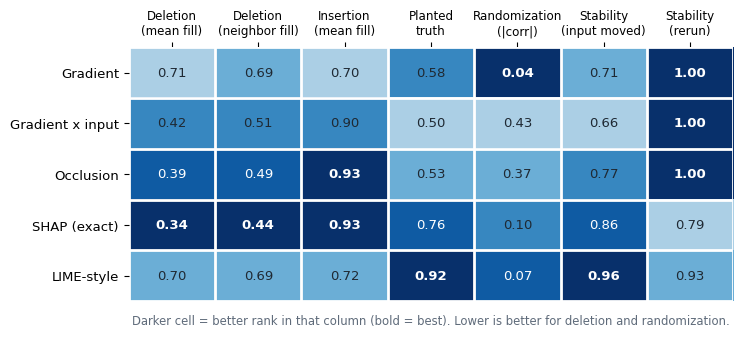

total time 48 seconds


In [9]:
FA, SRA, RC = disagreement(R)
scorecard(dres, refs, prec, corr, noise, rerun); plt.show()
print(f'total time {time.time() - T0:.0f} seconds')

**Checkpoint 7.** Mean feature agreement 0.573, mean signed rank agreement 0.181. In the scorecard, no method wins every column.

## Part G: optional edit

Change `SEED = 0` in Part A to `SEED = 1` and run all cells again. This retrains the network with a different initialization (the data stays the same). Note which verdicts in the scorecard survive and which move. With the pinned versions you should find that the broad pattern holds; record the exact numbers you get.

## Questions

1. Deletion and planted truth rank the methods almost in reverse. Explain why, using the difference between slopes and contributions.
2. Occlusion ranks `utilization` second for applicant 1, although the true risk ignores it for this applicant. Is occlusion unfaithful, or the model imperfect? How could you find out?
3. Which method would you choose for reason codes shown to applicants, and which for a developer looking for features the model should not use? Justify each with two columns of the scorecard.
4. Why does the average-value referee flatter occlusion and gradient times input?
5. Write the verdict paragraph of an evaluation report for SHAP on this model, with its settings and caveats.